# Fuga de clientes (churn) en telecomunicaciones: exploración y limpieza

**Pregunta de negocio:** ¿qué clientes se van y qué características los distinguen de los que se quedan?

Este notebook cubre la primera mitad del proyecto: entender y limpiar los datos. El modelo viene en el siguiente notebook.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

RAW = Path("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
PROCESADO = Path("../data/processed")
FIGURAS = Path("../reports/figures")
PROCESADO.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)

## 1. Carga y estructura

In [2]:
df = pd.read_csv(RAW)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

## 2. Calidad de los datos

Dos cosas que revisar siempre: valores nulos y duplicados. Además, `TotalCharges` debería ser numérica; si aparece como texto, hay algo escondido.

In [4]:
print("Nulos por columna (solo las que tienen):")
nulos = df.isna().sum()
print(nulos[nulos > 0] if (nulos > 0).any() else "ninguno")
print("\nIDs de cliente duplicados:", df["customerID"].duplicated().sum())
print("Tipo de TotalCharges:", df["TotalCharges"].dtype)

Nulos por columna (solo las que tienen):
ninguno

IDs de cliente duplicados: 0
Tipo de TotalCharges: object


In [5]:
# ¿Qué valores de TotalCharges no se pueden convertir a número?
convertido = pd.to_numeric(df["TotalCharges"], errors="coerce")
problemas = df[convertido.isna()]
print(len(problemas), "filas con TotalCharges no numérico")
problemas[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

11 filas con TotalCharges no numérico


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


Son clientes con `tenure` 0: se acaban de dar de alta y todavía no tienen ningún cobro acumulado. El valor correcto es 0, no un dato faltante.

In [6]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
assert (df.loc[df["TotalCharges"].isna(), "tenure"] == 0).all()
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Variable objetivo numérica (1 = se fue) y SeniorCitizen con las mismas etiquetas que el resto
df["churn"] = (df["Churn"] == "Yes").astype(int)
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

print("Nulos restantes:", int(df.isna().sum().sum()))
df[["TotalCharges", "churn"]].describe()

Nulos restantes: 0


,TotalCharges,churn
count,7043.000000,7043.000000
mean,2279.734304,0.265370
std,2266.794470,0.441561
min,0.000000,0.000000
25%,398.550000,0.000000
50%,1394.550000,0.000000
75%,3786.600000,1.000000
max,8684.800000,1.000000


## 3. Variable objetivo

Cuántos clientes se van. Si la clase está desbalanceada, la exactitud (accuracy) engaña: un modelo que dice "nadie se va" acertaría la mayoría de las veces y sería inútil.

Tasa de churn: 26.5%  (1869 de 7043 clientes)


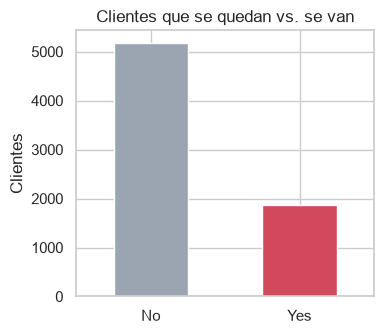

In [7]:
tasa = df["churn"].mean()
print(f"Tasa de churn: {tasa:.1%}  ({df['churn'].sum()} de {len(df)} clientes)")

fig, ax = plt.subplots(figsize=(4, 3.5))
df["Churn"].value_counts().reindex(["No", "Yes"]).plot.bar(ax=ax, color=["#9aa5b1", "#d1495b"])
ax.set_title("Clientes que se quedan vs. se van")
ax.set_xlabel("")
ax.set_ylabel("Clientes")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(FIGURAS / "01_distribucion_churn.png", dpi=150)
plt.show()

## 4. Churn según características del cliente

Para cada variable categórica calculamos el porcentaje de clientes que se fue en cada grupo. Una barra alta significa un grupo de mayor riesgo.

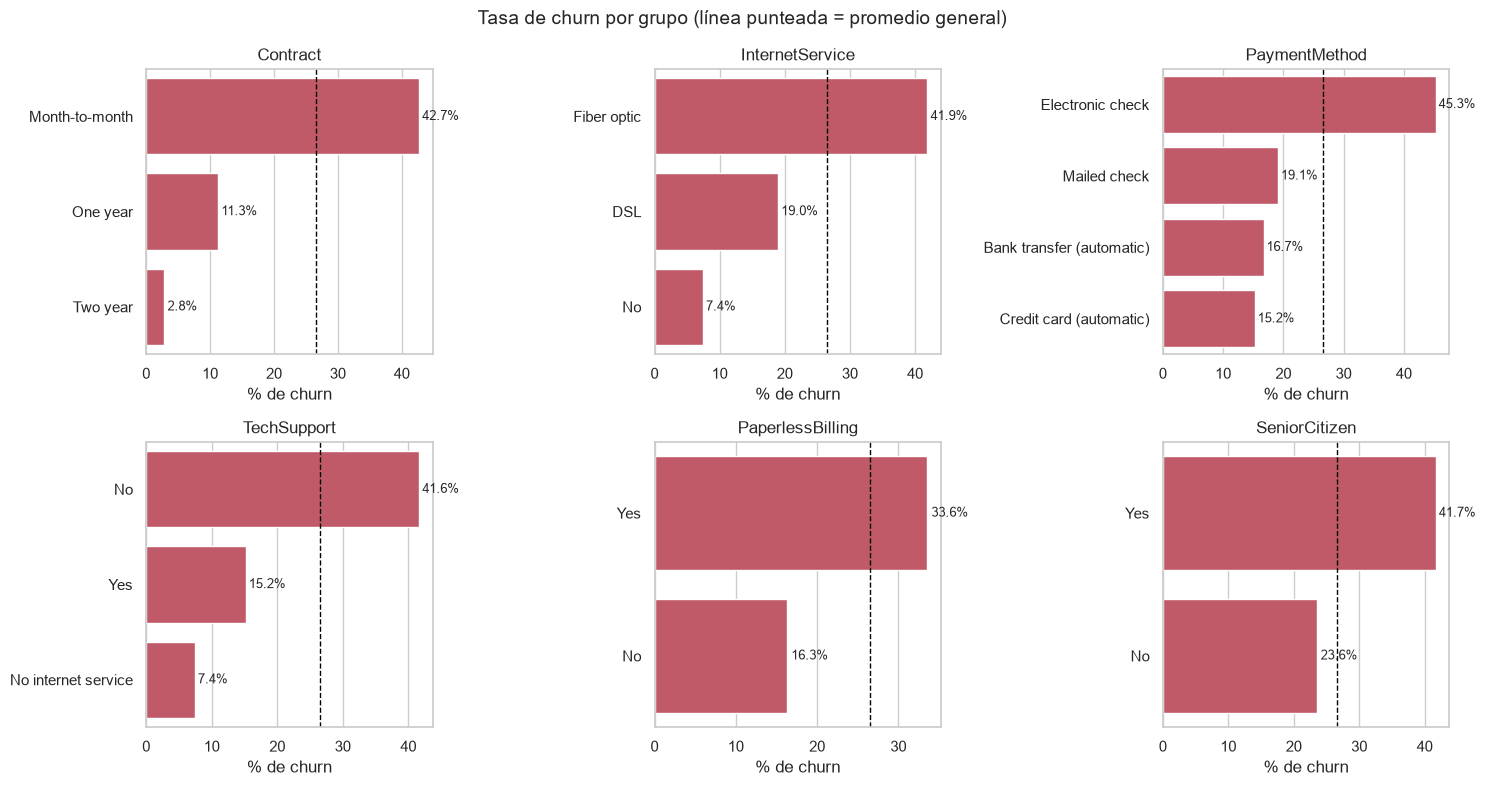

In [8]:
categoricas = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "PaperlessBilling", "SeniorCitizen"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), categoricas):
    tasas = df.groupby(col)["churn"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=tasas.values, y=tasas.index, ax=ax, color="#d1495b")
    ax.axvline(tasa * 100, color="black", linestyle="--", linewidth=1)
    ax.set_title(col)
    ax.set_xlabel("% de churn")
    ax.set_ylabel("")
    for i, v in enumerate(tasas.values):
        ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)
fig.suptitle("Tasa de churn por grupo (línea punteada = promedio general)", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURAS / "02_churn_por_categoria.png", dpi=150)
plt.show()

In [9]:
# La misma información en tablas, por si quieres leer los números exactos
for col in ["Contract", "InternetService", "PaymentMethod"]:
    t = df.groupby(col)["churn"].agg(clientes="count", tasa_churn="mean").round(3)
    print(t.sort_values("tasa_churn", ascending=False), "\n")

                clientes  tasa_churn
Contract                            
Month-to-month      3875       0.427
One year            1473       0.113
Two year            1695       0.028 

                 clientes  tasa_churn
InternetService                      
Fiber optic          3096       0.419
DSL                  2421       0.190
No                   1526       0.074 

                           clientes  tasa_churn
PaymentMethod                                  
Electronic check               2365       0.453
Mailed check                   1612       0.191
Bank transfer (automatic)      1544       0.167
Credit card (automatic)        1522       0.152 



## 5. Antigüedad y cargos

`tenure` son los meses que el cliente lleva en la empresa. Comparamos cómo se distribuyen quienes se van y quienes se quedan.

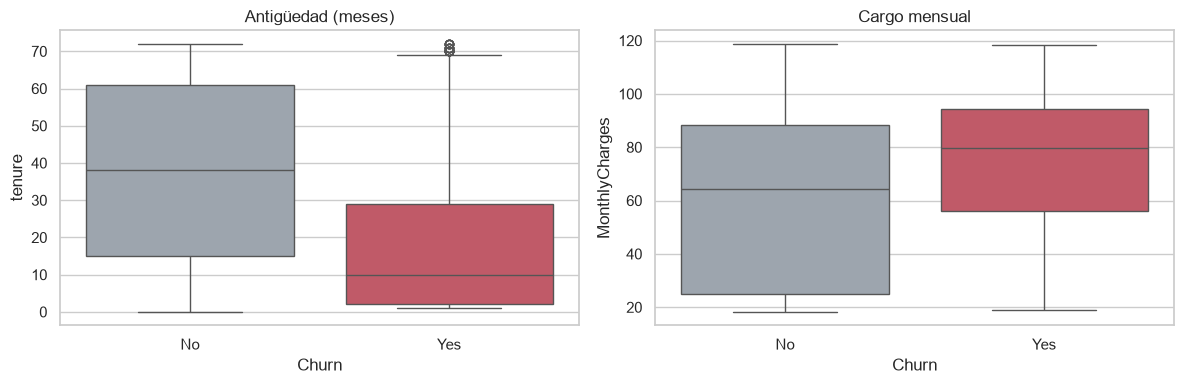

       tenure  MonthlyCharges
Churn                        
No       38.0          64.425
Yes      10.0          79.650


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="Churn", y="tenure", order=["No", "Yes"], hue="Churn", palette=["#9aa5b1", "#d1495b"], legend=False, ax=axes[0])
axes[0].set_title("Antigüedad (meses)")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", order=["No", "Yes"], hue="Churn", palette=["#9aa5b1", "#d1495b"], legend=False, ax=axes[1])
axes[1].set_title("Cargo mensual")
plt.tight_layout()
plt.savefig(FIGURAS / "03_tenure_cargos.png", dpi=150)
plt.show()

print(df.groupby("Churn")[["tenure", "MonthlyCharges"]].median())

        clientes  tasa_churn
tenure                      
0-12        2186       0.474
13-24       1024       0.287
25-48       1594       0.204
49-72       2239       0.095


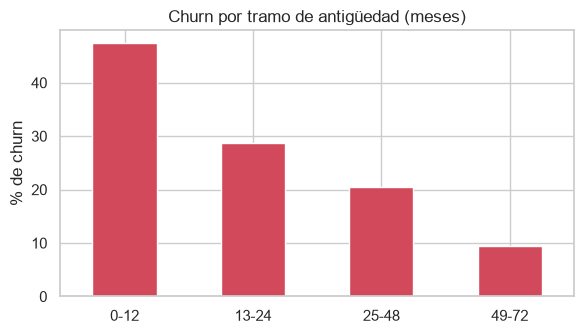

In [11]:
# Churn por tramo de antigüedad
tramos = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
por_tramo = df.groupby(tramos, observed=True)["churn"].agg(clientes="count", tasa_churn="mean").round(3)
print(por_tramo)

fig, ax = plt.subplots(figsize=(6, 3.5))
(por_tramo["tasa_churn"] * 100).plot.bar(ax=ax, color="#d1495b")
ax.set_title("Churn por tramo de antigüedad (meses)")
ax.set_xlabel("")
ax.set_ylabel("% de churn")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(FIGURAS / "04_churn_por_antiguedad.png", dpi=150)
plt.show()

## 6. Hallazgos

*Completa aquí con tus propias palabras, mirando los gráficos de arriba:*

1. Tipo de contrato:es la señal más fuerte. Los clientes con contrato mes a mes se van cerca de 43 % de las veces. Con contrato de un año baja a cerca de 11 %, y con contrato de dos años a cerca de 3 %. Los contratos largos retienen mucho mejor, aunque parte de esa diferencia es que quien ya se comprometió por dos años no puede irse todavía.
2. Antigüedad: La mediana de antigüedad de quienes se van es mucho menor que la de quienes se quedan (del orden de 10 meses frente a 38). En el tramo de 0 a 12 meses el churn ronda 47 %, y baja de forma sostenida en los tramos siguientes. Los primeros meses son la ventana crítica para retener.
3. Servicio de internet y medio de pago: La fibra óptica tiene cerca de 42 % de churn, contra cerca de 19 % en DSL y 7 % sin internet.
Quienes pagan con cheque electrónico se van cerca de 45 % de las veces, frente a 15-19 % en los demás medios. Los pagos automáticos (tarjeta o transferencia) son los de menor churn.

In [12]:
df.to_csv(PROCESADO / "telco_limpio.csv", index=False)
print("Guardado:", PROCESADO / "telco_limpio.csv", df.shape)

Guardado: ..\data\processed\telco_limpio.csv (7043, 22)
